# Datos Masivos — McCain: ¿dónde se vende la papa industrial en México?

**Entregable 2** · Pipeline reproducible: adquisición → procesamiento → validación → dataset preparado

En el entregable 1 construimos los extractores dentro del notebook. Ahora el trabajo vive en
`src/` y se corre desde la terminal; este notebook solo **llama** al pipeline y revisa lo
que produjo. Si borramos `data/raw`, `data/interim` y `data/processed`, todo se regenera
con estos cuatro comandos:

```bash
python -m src.ingestion.download_data
python -m src.processing.build_dataset
python -m src.validation.validate_dataset
python -m src.processing.benchmark
```

## 0. Preparar el entorno

Igual que en el E1: detectamos Colab, clonamos si hace falta, instalamos solo lo que
falte y resolvemos la raíz del repositorio para no depender de rutas personales.
Spark necesita Java; en Colab ya viene instalado.

In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/0267601/datos-masivos-mccain-papa.git"
CARPETA_REPO = "datos-masivos-mccain-papa"

try:
    import google.colab          # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB and not Path(CARPETA_REPO).exists():
    subprocess.check_call(["git", "clone", REPO_URL])

requisitos = {
    "pandas": "pandas>=2,<3",
    "pyspark": "pyspark>=3.5,<5",
    "yaml": "pyyaml>=6,<7",
    "bs4": "beautifulsoup4>=4.12,<5",
    "pyarrow": "pyarrow>=14,<22",
    "matplotlib": "matplotlib>=3.7,<4",
}
faltantes = [paquete for modulo, paquete in requisitos.items()
             if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])


def encontrar_raiz():
    """Buscamos hacia arriba la carpeta que contiene src/processing/build_dataset.py."""
    for candidata in [Path.cwd(), *Path.cwd().parents]:
        if (candidata / "src" / "processing" / "build_dataset.py").exists():
            return candidata
        if (candidata / CARPETA_REPO / "src" / "processing" / "build_dataset.py").exists():
            return candidata / CARPETA_REPO
    raise RuntimeError("No encontramos la raíz del repositorio.")


RAIZ = encontrar_raiz()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import os
os.chdir(RAIZ)        # los módulos resuelven rutas desde la raíz

print("Entorno:", "Google Colab" if EN_COLAB else "Local")
print("Raíz del repositorio:", RAIZ.name + "/")

Entorno: Local
Raíz del repositorio: datos-masivos-mccain-papa/


## 1. Adquisición

`MODO = "muestra"` reconstruye `data/raw/` a partir de las copias del E1 y no necesita
internet: así el notebook corre aunque el SIAP o el SNIIM estén caídos. `MODO = "completo"` descarga de
las fuentes (13 CSV del SIAP y 72 páginas del SNIIM, unos 5 minutos). En ambos casos los
archivos que ya existen se toman de la caché.

In [2]:
MODO = "muestra"      # cambia a "completo" para descargar de las fuentes

from src.ingestion import download_data

codigo = download_data.main(["--muestra"] if MODO == "muestra" else [])
print("Código de salida:", codigo)

Código de salida: 0


In [3]:
from src.utils.rutas import RAW

for carpeta in sorted(p for p in RAW.iterdir() if p.is_dir()):
    archivos = [a for a in carpeta.rglob("*") if a.is_file()]
    mb = sum(a.stat().st_size for a in archivos) / 1024**2
    print(f"data/raw/{carpeta.name:6s} | {len(archivos):3d} archivos | {mb:5.1f} MB")

data/raw/siap   |  13 archivos |   0.4 MB
data/raw/sniim  |  15 archivos |   0.8 MB


## 2. Procesamiento con Spark

`build_dataset` hace dos etapas y cada una arranca **de la capa anterior en disco**:

| Etapa | Qué hacemos |
|---|---|
| raw → interim | SIAP: leemos año por año y unificamos encabezados (schema drift), filtramos papa. SNIIM: `wholeTextFiles` + `flatMap` con BeautifulSoup para parsear los HTML en paralelo. Todo como texto. |
| interim → processed | Tipos, nombres en snake_case con unidad, estados estandarizados, duplicados, nulos, variables derivadas, Parquet particionado. Cruce SIAP × SNIIM: índice de canalización. |

In [4]:
import json
from src.processing import build_dataset
from src.utils.rutas import PROCESSED

codigo = build_dataset.main()
print("Código de salida:", codigo)

resumen = json.loads((PROCESSED / "resumen_build.json").read_text())
resumen["etapas"]["interim_a_processed"]

Código de salida: 0


{'siap': {'filas_interim': 3171,
  'filas_nulos_llave': 0,
  'filas_duplicadas': 0,
  'filas_processed': 3171},
 'sniim': {'filas_interim': 2683,
  'filas_nulos_llave': 0,
  'filas_duplicadas': 0,
  'filas_processed': 2683},
 'canalizacion_filas': 22,
 'segundos': 10.9}

## 3. Leer las capas procesadas

In [5]:
from pyspark.sql import functions as F
from src.utils.spark import crear_spark

spark = crear_spark("DatosMasivos-Notebook02")

siap = spark.read.parquet(str(PROCESSED / "siap_produccion"))
sniim = spark.read.parquet(str(PROCESSED / "sniim_precios"))
canal = spark.read.parquet(str(PROCESSED / "canalizacion"))

print("SIAP  :", siap.count(), "filas |", siap.rdd.getNumPartitions(), "particiones")
print("SNIIM :", sniim.count(), "filas |", sniim.rdd.getNumPartitions(), "particiones")
sniim.printSchema()

SIAP  : 3171 filas | 2 particiones
SNIIM : 2683 filas | 2 particiones
root
 |-- fecha: date (nullable = true)
 |-- presentacion: string (nullable = true)
 |-- origen: string (nullable = true)
 |-- destino: string (nullable = true)
 |-- precio_min: double (nullable = true)
 |-- precio_max: double (nullable = true)
 |-- precio_frec: double (nullable = true)
 |-- obs: string (nullable = true)
 |-- producto_id: integer (nullable = true)
 |-- archivo: string (nullable = true)
 |-- variedad: string (nullable = true)
 |-- estado_destino: string (nullable = true)
 |-- mercado: string (nullable = true)
 |-- es_importacion: boolean (nullable = true)
 |-- estado_origen: string (nullable = true)
 |-- estado_origen_llave: string (nullable = true)
 |-- estado_destino_llave: string (nullable = true)
 |-- rango_precio: double (nullable = true)
 |-- anio: integer (nullable = true)
 |-- mes: integer (nullable = true)



In [6]:
sniim.select("fecha", "variedad", "origen", "estado_destino", "mercado",
             "precio_frec", "es_importacion").show(5, truncate=False)

+----------+--------+--------+-------------------+-------------------------------+-----------+--------------+
|fecha     |variedad|origen  |estado_destino     |mercado                        |precio_frec|es_importacion|
+----------+--------+--------+-------------------+-------------------------------+-----------+--------------+
|2025-01-02|Alpha   |Coahuila|Baja California Sur|Unión de Comerciantes de La Paz|35.0       |false         |
|2025-01-03|Alpha   |Coahuila|Baja California Sur|Unión de Comerciantes de La Paz|35.0       |false         |
|2025-01-06|Alpha   |Coahuila|Baja California Sur|Unión de Comerciantes de La Paz|35.0       |false         |
|2025-01-07|Alpha   |Coahuila|Baja California Sur|Unión de Comerciantes de La Paz|35.0       |false         |
|2025-01-08|Alpha   |Coahuila|Baja California Sur|Unión de Comerciantes de La Paz|35.0       |false         |
+----------+--------+--------+-------------------+-------------------------------+-----------+--------------+
only showi

## 4. Partition pruning

Escribimos SNIIM particionado por `anio` y `mes`. Si filtramos un mes, Spark debería
saltarse las demás carpetas. Buscamos `PartitionFilters` en el plan.

In [7]:
enero = sniim.filter((F.col("anio") == 2025) & (F.col("mes") == 1))
enero.explain(mode="formatted")

== Physical Plan ==
* ColumnarToRow (2)
+- Scan parquet  (1)


(1) Scan parquet 
Output [20]: [fecha#1646, presentacion#1647, origen#1648, destino#1649, precio_min#1650, precio_max#1651, precio_frec#1652, obs#1653, producto_id#1654, archivo#1655, variedad#1656, estado_destino#1657, mercado#1658, es_importacion#1659, estado_origen#1660, estado_origen_llave#1661, estado_destino_llave#1662, rango_precio#1663, anio#1664, mes#1665]
Batched: true
Location: InMemoryFileIndex [file:.../datos-masivos-mccain-papa/data/processed/sniim_precios]
PartitionFilters: [isnotnull(anio#1664), isnotnull(mes#1665), (anio#1664 = 2025), (mes#1665 = 1)]
ReadSchema: struct<fecha:date,presentacion:string,origen:string,destino:string,precio_min:double,precio_max:double,precio_frec:double,obs:string,producto_id:int,archivo:string,variedad:string,estado_destino:string,mercado:string,es_importacion:boolean,estado_origen:string,estado_origen_llave:string,estado_destino_llave:string,rango_precio:double>

(2) ColumnarT

## 5. Predicate pushdown

En una columna que **no** es partición, el filtro baja a la lectura del Parquet:
buscamos `PushedFilters`.

In [8]:
caras = sniim.filter(F.col("precio_frec") > 30).select("variedad", "precio_frec")
caras.explain(mode="formatted")

== Physical Plan ==
* Project (4)
+- * Filter (3)
   +- * ColumnarToRow (2)
      +- Scan parquet  (1)


(1) Scan parquet 
Output [4]: [precio_frec#1652, variedad#1656, anio#1664, mes#1665]
Batched: true
Location: InMemoryFileIndex [file:.../datos-masivos-mccain-papa/data/processed/sniim_precios]
PushedFilters: [IsNotNull(precio_frec), GreaterThan(precio_frec,30.0)]
ReadSchema: struct<precio_frec:double,variedad:string>

(2) ColumnarToRow [codegen id : 1]
Input [4]: [precio_frec#1652, variedad#1656, anio#1664, mes#1665]

(3) Filter [codegen id : 1]
Input [4]: [precio_frec#1652, variedad#1656, anio#1664, mes#1665]
Condition : (isnotnull(precio_frec#1652) AND (precio_frec#1652 > 30.0))

(4) Project [codegen id : 1]
Output [2]: [variedad#1656, precio_frec#1652]
Input [4]: [precio_frec#1652, variedad#1656, anio#1664, mes#1665]




## 6. Broadcast y shuffle en el cruce

En `canalizacion.py` filtramos ambas tablas por los años comunes con un **broadcast**
(la lista de años es diminuta) y después hacemos un *full outer join*. Spark no puede
resolver un full outer con broadcast, así que ahí sí aparece un `Exchange`. Buscamos
ambos en el plan.

In [9]:
from src.processing.canalizacion import construir_canalizacion

plan = construir_canalizacion(siap, sniim)
plan.explain(mode="formatted")

== Physical Plan ==
AdaptiveSparkPlan (57)
+- Project (56)
   +- Window (55)
      +- Sort (54)
         +- Project (53)
            +- Project (52)
               +- Window (51)
                  +- Sort (50)
                     +- Exchange (49)
                        +- Project (48)
                           +- SortMergeJoin FullOuter (47)
                              :- Project (22)
                              :  +- BroadcastHashJoin Inner BuildRight (21)
                              :     :- SortAggregate (6)
                              :     :  +- Sort (5)
                              :     :     +- Exchange (4)
                              :     :        +- SortAggregate (3)
                              :     :           +- Sort (2)
                              :     :              +- Scan parquet  (1)
                              :     +- BroadcastExchange (20)
                              :        +- Project (19)
                              :           +- Broad

## 7. Validación

In [10]:
import pandas as pd
from src.validation import validate_dataset
from src.utils.rutas import TABLAS

codigo = validate_dataset.main()
print("Código de salida:", codigo)

validacion = pd.read_csv(TABLAS / "validacion.csv")
print(validacion.estado.value_counts().to_dict())
validacion[validacion.estado != "OK"]

Código de salida: 0
{'OK': 34, 'AVISO': 2}


,tabla,regla,estado,valor,detalle
31,siap x sniim,origenes SNIIM con produccion en SIAP,AVISO,2.0,"sin produccion en SIAP: ['Nayarit', 'Yucatán']"
35,sniim raw,particiones truncadas,AVISO,NaN,sin manifiesto (datos de muestra): no se puede...


## 8. Primer resultado del dataset preparado

`toPandas()` solo al final y sobre una tabla chica (una fila por estado).

In [11]:
# crear_spark otra vez: validate_dataset cierra su sesión al terminar.
spark = crear_spark("DatosMasivos-Notebook02")
canal = spark.read.parquet(str(PROCESSED / "canalizacion"))

ultimo = canal.agg(F.max("anio")).first()[0]
top = (
    canal.filter(F.col("anio") == ultimo)
    .orderBy("ranking")
    .select("ranking", "estado", "produccion_ton", "pct_nacional",
            "pct_mayoreo", "canalizacion")
)
top.show(10)

+-------+-------------------+------------------+--------------------+------------------+--------------------+
|ranking|             estado|    produccion_ton|        pct_nacional|       pct_mayoreo|        canalizacion|
+-------+-------------------+------------------+--------------------+------------------+--------------------+
|      1|             Sonora| 687679.0599999999|  30.751378734011652|               0.0|  30.751378734011652|
|      2|            Sinaloa| 605741.9600000001|  27.087345697341053| 17.40842851516345|   9.678917182177603|
|      3|         Nuevo León|          112310.0|   5.022237183747967|1.8511224891689642|  3.1711146945790025|
|      4|Baja California Sur|           48910.0|  2.1871393523026716|               0.0|  2.1871393523026716|
|      5|            Chiapas|          28764.69|  1.2862888050661854|               0.0|  1.2862888050661854|
|      6|         Guanajuato|           27573.2|  1.2330081944165205|               0.0|  1.2330081944165205|
|      7| 

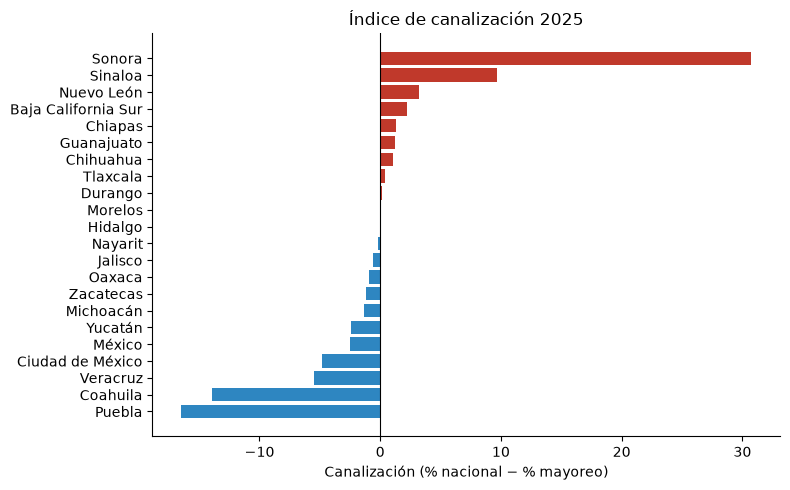

In [12]:
import matplotlib.pyplot as plt

top_pd = top.toPandas().sort_values("canalizacion")

fig, ax = plt.subplots(figsize=(8, 5))
colores = ["#c0392b" if v > 0 else "#2e86c1" for v in top_pd.canalizacion]
ax.barh(top_pd.estado, top_pd.canalizacion, color=colores)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Canalización (% nacional − % mayoreo)")
ax.set_title(f"Índice de canalización {ultimo}")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Con la muestra (enero–marzo de 2025) Sonora vuelve a quedar arriba: produce cerca del 31%
de la papa del país y no aparece en ninguna cotización del trimestre. Es el mismo patrón
del E1, ahora calculado por el pipeline y no a mano.

## 9. Desempeño

El detalle está en `docs/desempeno.md`. Aquí solo leemos la tabla que dejó
`python -m src.processing.benchmark`. La gráfica queda en
`reports/figures/desempeno_volumen.svg`.

In [13]:
desempeno = pd.read_csv(TABLAS / "desempeno.csv")
desempeno.pivot_table(index="filas", columns=["prueba", "variante", "motor"],
                      values="segundos").round(3).T

filas                                                  2683     26830    \
prueba                    variante             motor                      
A. lectura                CSV                  pandas    0.005    0.024   
                          Parquet              pandas    0.036    0.040   
B. agregacion             groupBy variedad     Spark     0.276    0.230   
                                               pandas    0.033    0.037   
C. filtro un mes          particionado por mes Spark     0.088    0.242   
                          sin particionar      Spark     0.117    0.094   
D. particiones de shuffle 16 particiones       Spark       NaN      NaN   
                          4 particiones        Spark       NaN      NaN   
                          8 particiones        Spark       NaN      NaN   

filas                                                  268300   1073200  
prueba                    variante             motor                     
A. lectura                CSV                  pandas    0.197    0.777  
                          Parquet              pandas    0.081    0.208  
B. agregacion             groupBy variedad     Spark     0.225    0.352  
                                               pandas    0.066    0.142  
C. filtro un mes          particionado por mes Spark     0.092    0.072  
                          sin particionar      Spark     0.088    0.100  
D. particiones de shuffle 16 particiones       Spark       NaN    0.028  
                          4 particiones        Spark       NaN    0.031  
                          8 particiones        Spark       NaN    0.031

In [14]:
spark.stop()

## 10. Conclusión del entregable

1. **Adquisición reproducible.** `download_data` guarda copia cruda, usa caché, registra
   errores sin detener la corrida y deja un manifiesto con sha256 por archivo.
2. **Tres capas.** raw (sin modificar) → interim (esquema unificado, texto) → processed
   (tipado, limpio, particionado).
3. **Validación.** 36 reglas en 8 categorías; los avisos quedan documentados y las fallas
   detienen el pipeline con código de salida 1.
4. **Desempeño.** Medimos formatos, motores y particionamiento con volumen replicado.
5. **Ya no dependemos del notebook.** Este notebook solo llama a `src/`.